<a href="https://colab.research.google.com/github/Sirinegaida/-Teaching-Proteins-to-Speak-Speech-Inspired-Embeddings-for-Biological-Discovery/blob/main/Teaching_Proteins_to_Speak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Teaching Proteins to Speak — proof-of-concept notebook
Reproduces the experiment of *“Teaching Proteins to Speak: Speech-Inspired Embeddings for Biological Discovery”*.

**Pipeline:** curated pathways → symbolic function tokens → speech-inspired transformer encoder (unsupervised, masked-token pretraining) → clustering → silhouette vs. randomized baselines → UMAP/PCA figures.

**What this notebook produces (in `outputs/`):** `results_table.csv` (Table 1), `fig_umap_pca.png` (UMAP/PCA, 300 dpi), `fig_silhouette.png`, `stats_summary.json`.

> ⚠️ **Report the numbers this notebook prints**, not the poster values. The encoder is trained *without* pathway labels; labels are used only to evaluate.

## 0. Setup

In [1]:
# !pip install torch scikit-learn umap-learn scipy pandas matplotlib
import os, json, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
import umap
warnings.filterwarnings("ignore")
os.makedirs("outputs", exist_ok=True)

# ---- experiment settings ----
N_SEEDS   = 20      # independent runs (training seed + init)
WINDOW    = 2       # neighbours on each side included in a protein's sequence
EPOCHS    = 60
D_MODEL, HEADS, LAYERS, FF = 64, 4, 3, 128   # 3 layers, as in the pipeline figure
N_PERM    = 1000    # label permutations for the randomized baseline
DEVICE    = "cpu"
torch.set_num_threads(2)

## 1. Curated pathways → ordered function tokens
Each pathway is an **ordered chain** of proteins; each protein carries 1–2 functional-role tokens (curated by hand from standard textbook annotations: UniProt / Reactome / KEGG).
Order follows pathway execution (cell-cycle G1/S → checkpoints → mitosis; glycolysis → TCA → ATP synthesis).

**Edit freely** — add proteins or replace this block with an automated KEGG/Reactome/GO export for the scale-up experiment.

In [2]:
PATHWAYS = {
 "Cell cycle regulation": [
  ("CCND1",["signal","bind"]), ("CDK4",["bind","phosphorylate"]), ("RB1",["inhibit","release"]),
  ("E2F1",["transcribe","activate"]), ("CCNE1",["bind","activate"]), ("CDK2",["phosphorylate","activate"]),
  ("CDC25A",["dephosphorylate","activate"]), ("ATM",["sense","phosphorylate"]), ("TP53",["check","transcribe","pause"]),
  ("CDKN1A",["inhibit","pause"]), ("CHEK2",["phosphorylate","pause"]), ("WEE1",["phosphorylate","inhibit"]),
  ("CCNB1",["bind","activate"]), ("CDK1",["phosphorylate","execute"]), ("PLK1",["phosphorylate","execute"]),
  ("AURKB",["phosphorylate","check"]), ("MAD2L1",["check","inhibit"]), ("CDC20",["activate","degrade"]),
  ("ANAPC1",["degrade","execute"]), ("ESPL1",["cleave","execute"]),
 ],
 "Core metabolic processes": [
  ("SLC2A1",["transport"]), ("HK1",["phosphorylate","catalyze"]), ("GPI",["isomerize","catalyze"]),
  ("PFKM",["phosphorylate","catalyze"]), ("ALDOA",["cleave","catalyze"]), ("TPI1",["isomerize","catalyze"]),
  ("GAPDH",["oxidize","catalyze"]), ("PGK1",["phosphorylate","synthesize"]), ("PGAM1",["isomerize","catalyze"]),
  ("ENO1",["dehydrate","catalyze"]), ("PKM",["phosphorylate","synthesize"]), ("PDHA1",["oxidize","release"]),
  ("CS",["synthesize","catalyze"]), ("ACO2",["isomerize","catalyze"]), ("IDH3A",["oxidize","release"]),
  ("OGDH",["oxidize","release"]), ("SUCLA2",["synthesize","phosphorylate"]), ("SDHA",["oxidize","catalyze"]),
  ("FH",["hydrate","catalyze"]), ("MDH2",["oxidize","catalyze"]), ("ATP5F1A",["synthesize","transport"]),
 ],
}
LABELS = list(PATHWAYS)

# Coarse vocabulary used by the *leakage control* (Section 6): maps many specific roles to few generic actions,
# so that the two pathways share most of their tokens.
COARSE = {"signal":"regulate","sense":"regulate","check":"regulate","inhibit":"regulate","activate":"regulate","pause":"regulate",
          "bind":"bind","phosphorylate":"modify","dephosphorylate":"modify","oxidize":"modify","isomerize":"modify",
          "dehydrate":"modify","hydrate":"modify","transcribe":"make","synthesize":"make","release":"move","transport":"move",
          "degrade":"cleave","cleave":"cleave","execute":"act","catalyze":"act"}

SPECIAL = ["[PAD]","[MASK]","[CLS]","[SEP]"]
def build_vocab(tokens): return {t:i for i,t in enumerate(SPECIAL+sorted(tokens))}

def build_sequences(window=WINDOW, vocab_map=None, shuffle_rng=None):
    """One symbolic sequence per protein: [CLS] + tokens of the protein and its +-window neighbours in pathway order,
    proteins separated by [SEP]. If shuffle_rng is given, tokens are shuffled (temporal-order ablation)."""
    rows=[]
    for y,(pw,chain) in enumerate(PATHWAYS.items()):
        for i,(prot,_) in enumerate(chain):
            seq=["[CLS]"]
            for j in range(max(0,i-window), min(len(chain),i+window+1)):
                toks=[(vocab_map or {}).get(t,t) for t in chain[j][1]]
                seq += toks+["[SEP]"]
            if shuffle_rng is not None:
                body=seq[1:]; shuffle_rng.shuffle(body); seq=["[CLS]"]+body
            rows.append(dict(protein=prot,pathway=pw,label=y,tokens=seq))
    return pd.DataFrame(rows)

df=build_sequences()
print(df.groupby("pathway").size())
df.head(3)

pathway
Cell cycle regulation       20
Core metabolic processes    21
dtype: int64


,protein,pathway,label,tokens
0,CCND1,Cell cycle regulation,0,"[[CLS], signal, bind, [SEP], bind, phosphoryla..."
1,CDK4,Cell cycle regulation,0,"[[CLS], signal, bind, [SEP], bind, phosphoryla..."
2,RB1,Cell cycle regulation,0,"[[CLS], signal, bind, [SEP], bind, phosphoryla..."


## 2. Speech-inspired transformer encoder
Symbolic tokens play the role of discrete speech units. The encoder mirrors the structure of speech models (wav2vec 2.0 / HuBERT):
1. token embedding,
2. **depthwise 1-D convolution** with a residual connection (local temporal context, like the convolutional positional embedding in wav2vec 2.0),
3. a **3-layer Transformer encoder** with multi-head self-attention,
4. **HuBERT-style masked prediction** of hidden tokens as the self-supervised objective (**no pathway labels are used**),
5. mean pooling → one embedding per protein. Only the encoder is used; there is no audio synthesis.

In [3]:
class SpeechInspiredEncoder(nn.Module):
    def __init__(self, vocab_size, d=D_MODEL, heads=HEADS, layers=LAYERS, ff=FF, dropout=0.1, kernel=5):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, d, padding_idx=0)
        self.conv = nn.Conv1d(d, d, kernel, padding=kernel//2, groups=d)
        self.act, self.norm = nn.GELU(), nn.LayerNorm(d)
        layer = nn.TransformerEncoderLayer(d, heads, ff, dropout, activation="gelu", batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, vocab_size)           # masked-token prediction head

    def forward(self, ids):
        pad = ids.eq(0)
        x = self.emb(ids)
        x = self.norm(x + self.act(self.conv(x.transpose(1,2))).transpose(1,2))
        return self.encoder(x, src_key_padding_mask=pad), pad

    def embed(self, ids):
        h, pad = self.forward(ids)
        m = (~pad).unsqueeze(-1).float()
        return (h*m).sum(1)/m.sum(1)                   # masked mean pooling

def to_tensor(df, vocab):
    L=max(len(t) for t in df.tokens)
    ids=torch.zeros(len(df),L,dtype=torch.long)
    for r,t in enumerate(df.tokens): ids[r,:len(t)]=torch.tensor([vocab[x] for x in t])
    return ids

def pretrain(model, ids, vocab, epochs=EPOCHS, lr=1e-3, p_mask=0.25, bs=16):
    opt=torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    maskable=(ids>=len(SPECIAL))                       # never mask PAD/CLS/SEP/MASK
    model.train()
    for ep in range(epochs):
        perm=torch.randperm(len(ids))
        for b in range(0,len(ids),bs):
            x=ids[perm[b:b+bs]]; ok=maskable[perm[b:b+bs]]
            m=(torch.rand(x.shape)<p_mask)&ok
            if m.sum()==0: continue
            xin=x.clone(); xin[m]=vocab["[MASK]"]
            h,_=model(xin); loss=nn.functional.cross_entropy(model.head(h[m]), x[m])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); return model

## 3. One experimental run
`run(seed, condition)` builds sequences, (optionally) pretrains the encoder, embeds all proteins and computes:
* **silhouette (pathway labels)** – cosine silhouette of the embeddings w.r.t. the true pathway membership,
* **silhouette (k-means)** – silhouette of an unsupervised k-means (k = 2) partition,
* **ARI / NMI** – agreement between the k-means partition and the pathway labels.

| condition | meaning |
|---|---|
| `trained` | **proposed method** |
| `untrained` | randomized baseline: same architecture, random weights |
| `shuffled_order` | ablation: tokens shuffled → tests whether *temporal order* matters |
| `coarse_vocab` | leakage control: generic shared vocabulary instead of specific roles |
| `bag_of_tokens` | non-neural baseline: token counts (no transformer, no order) |

In [4]:
def metrics(Z, y, seed):
    km=KMeans(2, n_init=10, random_state=seed).fit(Z)
    return dict(sil_labels=silhouette_score(Z,y,metric="cosine"),
                sil_kmeans=silhouette_score(Z,km.labels_,metric="cosine"),
                ARI=adjusted_rand_score(y,km.labels_), NMI=normalized_mutual_info_score(y,km.labels_))

def perm_pvalue(Z, y, rng, n=N_PERM):
    obs=silhouette_score(Z,y,metric="cosine")
    null=np.array([silhouette_score(Z, rng.permutation(y), metric="cosine") for _ in range(n)])
    return obs, null, (1+(null>=obs).sum())/(n+1)

def run(seed, condition, return_Z=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    vmap = COARSE if condition=="coarse_vocab" else None
    rng  = random.Random(seed) if condition=="shuffled_order" else None
    d    = build_sequences(vocab_map=vmap, shuffle_rng=rng)
    vocab= build_vocab({t for s in d.tokens for t in s if t not in SPECIAL})
    y    = d.label.values
    if condition=="bag_of_tokens":
        Z=CountVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None)\
            .fit_transform(d.tokens.map(" ".join)).toarray().astype(float)
    else:
        ids=to_tensor(d,vocab); model=SpeechInspiredEncoder(len(vocab)).to(DEVICE)
        if condition!="untrained": pretrain(model,ids,vocab)
        model.eval()
        with torch.no_grad(): Z=model.embed(ids).numpy()
    out=metrics(Z,y,seed)
    return (out,Z,d) if return_Z else out

# quick smoke test
run(0,"trained")

{'sil_labels': np.float32(0.690907),
 'sil_kmeans': np.float32(0.690907),
 'ARI': 1.0,
 'NMI': np.float64(1.0)}

## 4. Run all conditions over independent seeds

In [5]:
CONDITIONS=["trained","untrained","shuffled_order","coarse_vocab","bag_of_tokens"]
records=[]; STORE={}                                  # STORE keeps embeddings for the statistics/figures below
for cond in CONDITIONS:
    n = 1 if cond=="bag_of_tokens" else N_SEEDS     # bag-of-tokens is deterministic
    for s in range(n):
        out,Z,d = run(s,cond,return_Z=True)
        STORE[(cond,s)]=(Z,d.label.values)
        records.append(dict(condition=cond, seed=s, **out))
    print(f"{cond:15s} done")
res=pd.DataFrame(records)
res.to_csv("outputs/all_runs.csv", index=False)
res.groupby("condition")[["sil_labels","sil_kmeans","ARI","NMI"]].agg(["mean","std"]).round(3)

trained         done
untrained       done
shuffled_order  done
coarse_vocab    done
bag_of_tokens   done


sil_labels        sil_kmeans           ARI           NMI       
                     mean    std       mean    std   mean    std   mean    std
condition                                                                     
bag_of_tokens       0.595    NaN      0.595    NaN  1.000    NaN  1.000    NaN
coarse_vocab        0.647  0.099      0.677  0.090  0.881  0.212  0.879  0.197
shuffled_order      0.694  0.083      0.699  0.081  0.977  0.082  0.974  0.088
trained             0.701  0.067      0.702  0.066  0.986  0.062  0.984  0.070
untrained           0.560  0.093      0.563  0.087  0.971  0.129  0.973  0.119

## 5. Statistics: trained encoder vs. randomized baselines
* **Label-permutation test** (1000 shuffles of the pathway labels on the trained embeddings) → *p*-value.
* **Welch t-test + Cohen's d** across seeds: trained vs. untrained (random-weights) encoder.
* The **ratio** trained / baseline is reported (this is the “×  better than random” number for the poster/paper).

In [6]:
def cohen_d(a,b):
    na,nb=len(a),len(b); sp=np.sqrt(((na-1)*a.var(ddof=1)+(nb-1)*b.var(ddof=1))/(na+nb-2)); return (a.mean()-b.mean())/sp

tr =res[res.condition=="trained"].sil_labels.values
un =res[res.condition=="untrained"].sil_labels.values
t,p_welch=stats.ttest_ind(tr,un,equal_var=False)

# permutation test on every trained seed, report median p and the null mean
rng=np.random.default_rng(0); pvals=[]; null_means=[]
for s in range(N_SEEDS):
    Z,lab=STORE[("trained",s)]; obs,null,p=perm_pvalue(Z,lab,rng,n=N_PERM)
    pvals.append(p); null_means.append(null.mean())

summary=dict(
  silhouette_trained_mean=float(tr.mean()), silhouette_trained_std=float(tr.std(ddof=1)),
  silhouette_untrained_mean=float(un.mean()), silhouette_untrained_std=float(un.std(ddof=1)),
  silhouette_label_permutation_null_mean=float(np.mean(null_means)),
  ratio_trained_over_untrained=float(tr.mean()/un.mean()) if un.mean()>0 else None,
  welch_t=float(t), welch_p=float(p_welch), cohens_d=float(cohen_d(tr,un)),
  permutation_p_median=float(np.median(pvals)), permutation_p_max=float(np.max(pvals)),
  n_seeds=N_SEEDS, n_permutations=N_PERM)
json.dump(summary,open("outputs/stats_summary.json","w"),indent=2)
pd.Series(summary).round(4)

,0
silhouette_trained_mean,0.7015
silhouette_trained_std,0.0666
silhouette_untrained_mean,0.5600
silhouette_untrained_std,0.0925
silhouette_label_permutation_null_mean,0.0001
ratio_trained_over_untrained,1.2527
welch_t,5.5512
welch_p,0.0000
cohens_d,1.7554
permutation_p_median,0.0010


In [7]:
# ---- Table 1 for the paper (mean ± std over seeds) ----
nice={"trained":"Speech-inspired encoder (ours)","untrained":"Randomized baseline (untrained encoder)",
      "shuffled_order":"Ablation: shuffled token order","coarse_vocab":"Control: coarse shared vocabulary",
      "bag_of_tokens":"Bag-of-tokens (no transformer)"}
rows=[]
for c in CONDITIONS:
    r=res[res.condition==c]; f=lambda col:(f"{r[col].mean():.2f} ± {r[col].std(ddof=1):.2f}" if len(r)>1 else f"{r[col].iloc[0]:.2f}")
    rows.append({"Embedding":nice[c],"Silhouette (labels)":f("sil_labels"),"Silhouette (k-means, k=2)":f("sil_kmeans"),"ARI":f("ARI"),"NMI":f("NMI")})
table1=pd.DataFrame(rows); table1.to_csv("outputs/results_table.csv",index=False); table1

,Embedding,Silhouette (labels),"Silhouette (k-means, k=2)",ARI,NMI
0,Speech-inspired encoder (ours),0.70 ± 0.07,0.70 ± 0.07,0.99 ± 0.06,0.98 ± 0.07
1,Randomized baseline (untrained encoder),0.56 ± 0.09,0.56 ± 0.09,0.97 ± 0.13,0.97 ± 0.12
2,Ablation: shuffled token order,0.69 ± 0.08,0.70 ± 0.08,0.98 ± 0.08,0.97 ± 0.09
3,Control: coarse shared vocabulary,0.65 ± 0.10,0.68 ± 0.09,0.88 ± 0.21,0.88 ± 0.20
4,Bag-of-tokens (no transformer),0.60,0.60,1.00,1.00


## 6. How to read the results (important for the paper)
* `trained` > `untrained` supports that the *learned* embedding structure is not an artefact of the architecture.
* `shuffled_order` close to `trained` ⇒ order is **not** what drives the clustering (then the “temporal” claim should be softened).
* `coarse_vocab` and `bag_of_tokens` tell you how much of the result comes from **vocabulary design alone** (hand-built tokens can leak pathway identity). If `bag_of_tokens` matches `trained`, say so in the Discussion — it is a limitation, and reviewers will ask.
* ⚠️ **Expect `bag_of_tokens` to separate the two pathways almost perfectly on this hand-curated set** (in our check of the data, token counts alone gave ARI = 1.0, even with the coarse vocabulary). That means this toy dataset cannot show an *advantage* of the transformer over simple counts; say so honestly, and use the scale-up (KEGG/Reactome/GO, overlapping vocabularies, pathways that share functions) to test the real claim.
* With ~40 proteins and 2 pathways this remains a **small proof of concept**; keep the paper's “exploratory” wording.

## 7. Figures (300 dpi, readable in grayscale)

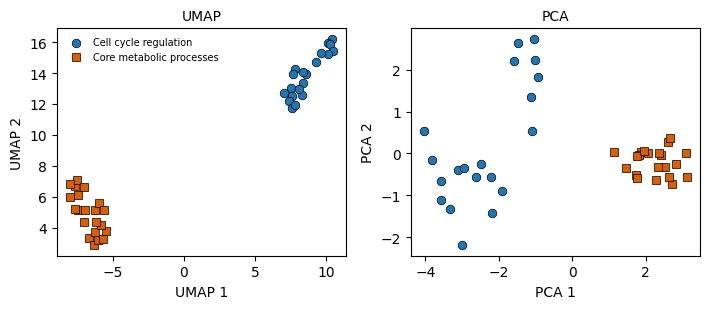

In [8]:
Z,y=STORE[("trained",0)]
Zp=PCA(2,random_state=0).fit_transform(Z)
Zu=umap.UMAP(n_neighbors=10,min_dist=0.3,metric="cosine",random_state=0).fit_transform(Z)
style={0:dict(marker="o",c="#1f77b4",label=LABELS[0]),1:dict(marker="s",c="#d95f02",label=LABELS[1])}
fig,ax=plt.subplots(1,2,figsize=(7.2,3.2))
for a,E,t in zip(ax,[Zu,Zp],["UMAP","PCA"]):
    for k in (0,1):
        m=y==k; a.scatter(E[m,0],E[m,1],s=38,edgecolor="k",linewidth=.5,marker=style[k]["marker"],c=style[k]["c"],label=style[k]["label"])
    a.set_xlabel(f"{t} 1"); a.set_ylabel(f"{t} 2"); a.set_title(t,fontsize=10)
ax[0].legend(fontsize=7,frameon=False,loc="best")
plt.tight_layout(); plt.savefig("outputs/fig_umap_pca.png",dpi=300); plt.show()

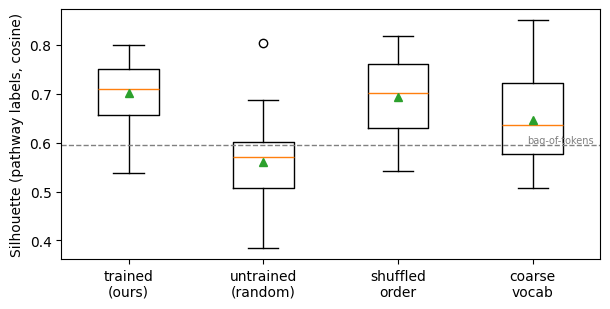

In [9]:
order=["trained","untrained","shuffled_order","coarse_vocab","bag_of_tokens"]
data=[res[res.condition==c].sil_labels.values for c in order]
fig,ax=plt.subplots(figsize=(6.2,3.2))
ax.boxplot(data[:4],labels=["trained\n(ours)","untrained\n(random)","shuffled\norder","coarse\nvocab"],showmeans=True)
ax.axhline(data[4][0],ls="--",c="gray",lw=1); ax.text(4.45,data[4][0],"bag-of-tokens",ha="right",va="bottom",fontsize=7,color="gray")
ax.set_ylabel("Silhouette (pathway labels, cosine)"); plt.tight_layout()
plt.savefig("outputs/fig_silhouette.png",dpi=300); plt.show()

## 8. Using the results in the Springer paper
1. Copy **`outputs/results_table.csv`** into *Table 1* (keep the two rows ours / randomized baseline; the others are optional ablation rows).
2. Use **`outputs/fig_umap_pca.png`** as the full-size UMAP figure (Fig. 2).
3. Copy the *p*-value, Cohen's *d*, ratio and *k* = 2 from the summary above; state in §5 that **N seeds = 20, window = 2, 3 layers, d = 64, 4 heads, masked-token pretraining for 60 epochs**.
4. Cite databases (KEGG / Reactome / UniProt, access date) for the curated annotations.